In [ ]:
# Librerías principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Separación y validación de datos
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Preprocesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Métricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# Dataset del caso de Recursos Humanos
data = {
    "edad": [
        25, 28, 35, 40, 30, 45, 32, 29, 50, 38,
        27, 33, 41, 36, 31, 48, 26, 39, 42, 34
    ],

    "salario": [
        1800, 2000, 3500, 4500, 2200, 5000, 2800, 2100, 6000, 4000,
        1900, 3000, 4700, 3600, 2500, 5500, 1700, 4200, 4800, 3200
    ],

    "años_empresa": [
        1, 2, 5, 8, 2, 10, 4, 2, 15, 7,
        1, 4, 9, 6, 3, 12, 1, 8, 10, 5
    ],

    "satisfaccion": [
        2, 3, 7, 8, 3, 9, 5, 2, 9, 7,
        2, 6, 8, 6, 4, 9, 1, 7, 8, 5
    ],

    "horas_extra": [
        15, 12, 5, 4, 14, 3, 8, 13, 2, 6,
        16, 7, 4, 6, 10, 3, 18, 5, 4, 8
    ],

    "renuncia": [
        1, 1, 0, 0, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 0, 1, 0, 1, 0, 0, 0
    ]
}

# Convertir a DataFrame
df = pd.DataFrame(data)

df

,edad,salario,años_empresa,satisfaccion,horas_extra,renuncia
0,25,1800,1,2,15,1
1,28,2000,2,3,12,1
2,35,3500,5,7,5,0
3,40,4500,8,8,4,0
4,30,2200,2,3,14,1
5,45,5000,10,9,3,0
6,32,2800,4,5,8,0
7,29,2100,2,2,13,1
8,50,6000,15,9,2,0
9,38,4000,7,7,6,0


In [ ]:
# Información general del dataset
print("Dimensiones:", df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores nulos:")
print(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nResumen estadístico:")
display(df.describe())

Dimensiones: (20, 6)

Tipos de datos:
edad            int64
salario         int64
años_empresa    int64
satisfaccion    int64
horas_extra     int64
renuncia        int64
dtype: object

Valores nulos:
edad            0
salario         0
años_empresa    0
satisfaccion    0
horas_extra     0
renuncia        0
dtype: int64

Registros duplicados:
0

Resumen estadístico:


,edad,salario,años_empresa,satisfaccion,horas_extra,renuncia
count,20.000000,20.000000,20.000000,20.000000,20.000000,20.00000
mean,35.450000,3450.000000,5.750000,5.550000,8.150000,0.35000
std,7.294374,1332.784975,4.024595,2.665076,4.891184,0.48936
min,25.000000,1700.000000,1.000000,1.000000,2.000000,0.00000
25%,29.750000,2175.000000,2.000000,3.000000,4.000000,0.00000
50%,34.500000,3350.000000,5.000000,6.000000,6.500000,0.00000
75%,40.250000,4550.000000,8.250000,8.000000,12.250000,1.00000
max,50.000000,6000.000000,15.000000,9.000000,18.000000,1.00000


renuncia
0    13
1     7
Name: count, dtype: int64

Distribución porcentual:
renuncia
0    65.0
1    35.0
Name: proportion, dtype: float64


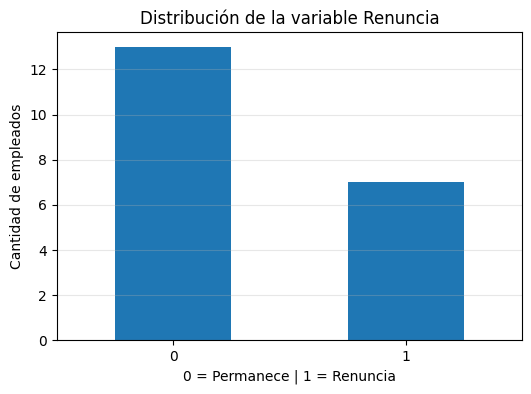

In [ ]:
# Distribución de empleados que permanecen y renuncian
print(df["renuncia"].value_counts())

print("\nDistribución porcentual:")
print(df["renuncia"].value_counts(normalize=True) * 100)

df["renuncia"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribución de la variable Renuncia")
plt.xlabel("0 = Permanece | 1 = Renuncia")
plt.ylabel("Cantidad de empleados")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
# Variables predictoras
X = df[
    [
        "edad",
        "salario",
        "años_empresa",
        "satisfaccion",
        "horas_extra"
    ]
]

# Variable objetivo
y = df["renuncia"]

print("Variables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

Variables predictoras:
['edad', 'salario', 'años_empresa', 'satisfaccion', 'horas_extra']

Variable objetivo:
renuncia


In [ ]:
# 70% entrenamiento y 30% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

print("\nClases en entrenamiento:")
print(y_train.value_counts())

print("\nClases en prueba:")
print(y_test.value_counts())

Datos de entrenamiento: 14
Datos de prueba: 6

Clases en entrenamiento:
renuncia
0    9
1    5
Name: count, dtype: int64

Clases en prueba:
renuncia
0    4
1    2
Name: count, dtype: int64


In [ ]:
# Modelos de clasificación
modelos = {

    "Regresión Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000))
    ]),

    "Árbol de Decisión": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=3))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", SVC(kernel="linear"))
    ]),

    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", GaussianNB())
    ])
}

print("Modelos creados:")
for nombre in modelos:
    print("-", nombre)

Modelos creados:
- Regresión Logística
- Árbol de Decisión
- Random Forest
- KNN
- SVM
- Naive Bayes


In [ ]:
# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Guardar resultados
resultados = []
predicciones = {}

for nombre, modelo in modelos.items():

    # Entrenamiento
    modelo.fit(X_train, y_train)

    # Predicciones
    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)

    predicciones[nombre] = y_pred_test

    # Métricas de prueba
    accuracy = accuracy_score(y_test, y_pred_test)
    precision = precision_score(y_test, y_pred_test, zero_division=0)
    recall = recall_score(y_test, y_pred_test, zero_division=0)
    f1 = f1_score(y_test, y_pred_test, zero_division=0)

    # Métrica de entrenamiento
    accuracy_train = accuracy_score(y_train, y_pred_train)

    # Validación cruzada
    cv_accuracy = cross_val_score(
        modelo,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_f1 = cross_val_score(
        modelo,
        X,
        y,
        cv=cv,
        scoring="f1"
    )

    resultados.append({
        "Modelo": nombre,
        "Accuracy Train": accuracy_train,
        "Accuracy Test": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "CV Accuracy": cv_accuracy.mean(),
        "CV F1": cv_f1.mean()
    })

print("Entrenamiento finalizado.")

Entrenamiento finalizado.


In [ ]:
# Crear tabla con resultados
df_resultados = pd.DataFrame(resultados)

# Ordenar por F1-Score
df_resultados = df_resultados.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(
    df_resultados.style.format({
        "Accuracy Train": "{:.3f}",
        "Accuracy Test": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-Score": "{:.3f}",
        "CV Accuracy": "{:.3f}",
        "CV F1": "{:.3f}"
    })
)

,Modelo,Accuracy Train,Accuracy Test,Precision,Recall,F1-Score,CV Accuracy,CV F1
0,Regresión Logística,1.000,1.000,1.000,1.000,1.000,1.000,1.000
1,Árbol de Decisión,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,1.000
3,KNN,1.000,1.000,1.000,1.000,1.000,1.000,1.000
4,SVM,1.000,1.000,1.000,1.000,1.000,1.000,1.000
5,Naive Bayes,1.000,0.833,1.000,0.500,0.667,0.950,0.933


In [ ]:
# Reporte detallado de cada modelo
for nombre in modelos:

    print("\n" + "=" * 70)
    print(nombre)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predicciones[nombre],
            target_names=["Permanece", "Renuncia"],
            zero_division=0
        )
    )


Regresión Logística
              precision    recall  f1-score   support

   Permanece       1.00      1.00      1.00         4
    Renuncia       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6


Árbol de Decisión
              precision    recall  f1-score   support

   Permanece       1.00      1.00      1.00         4
    Renuncia       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6


Random Forest
              precision    recall  f1-score   support

   Permanece       1.00      1.00      1.00         4
    Renuncia       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       

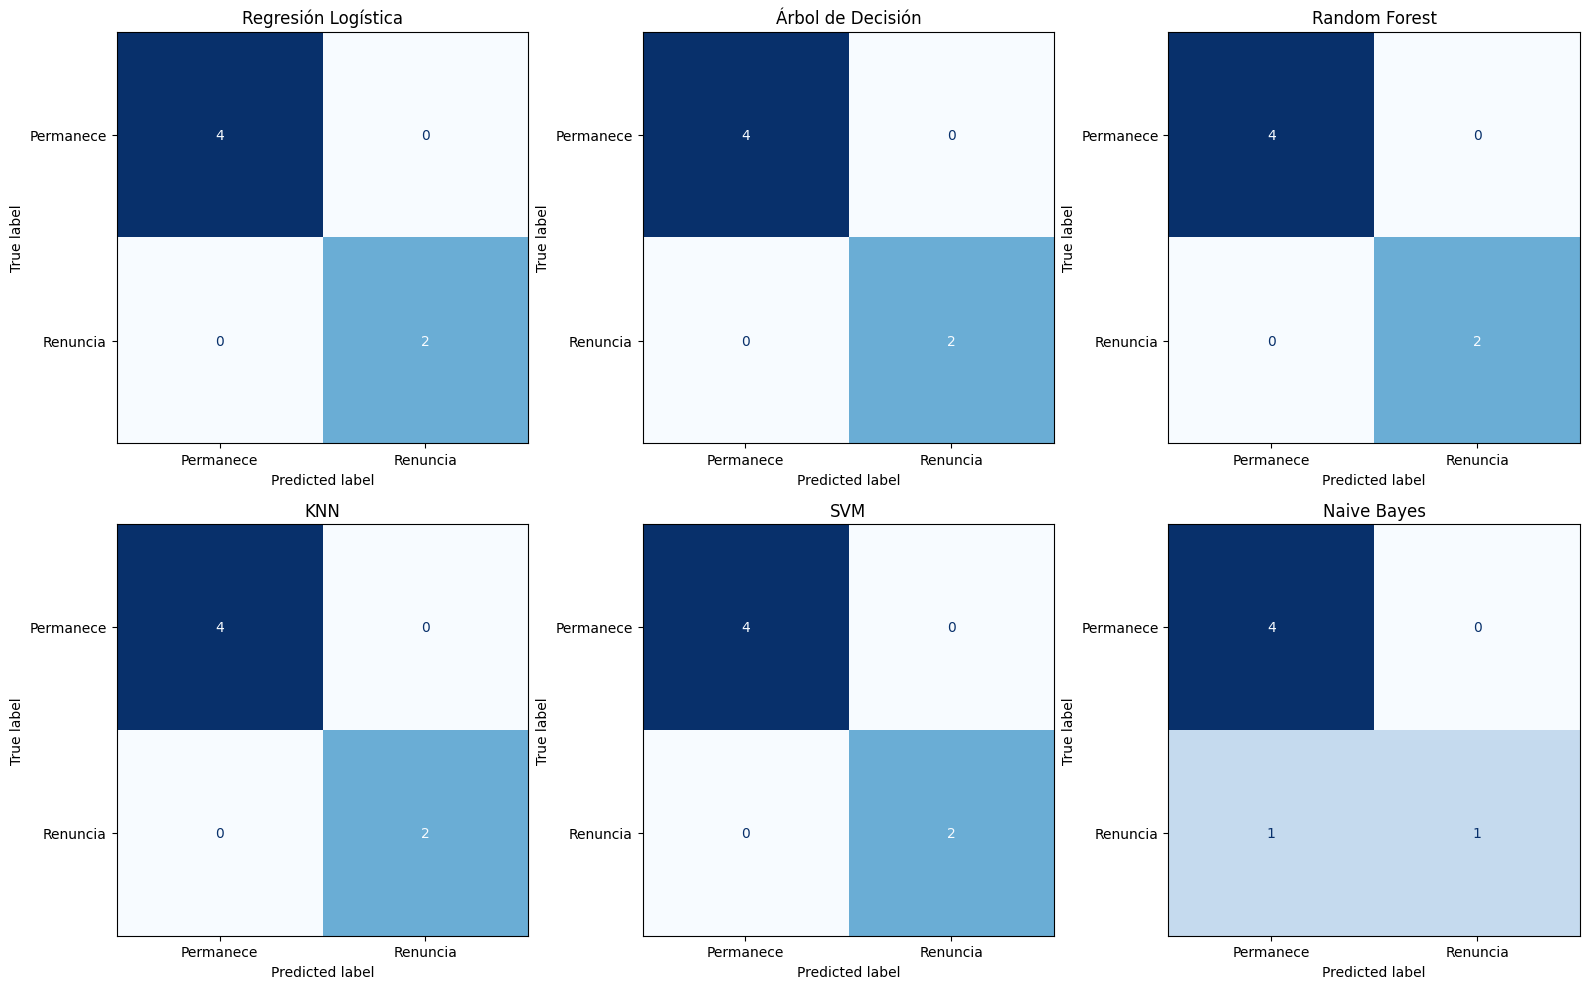

In [ ]:
# Matrices de confusión
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for ax, (nombre, y_pred) in zip(
    axes,
    predicciones.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Permanece", "Renuncia"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(nombre)

plt.tight_layout()
plt.show()

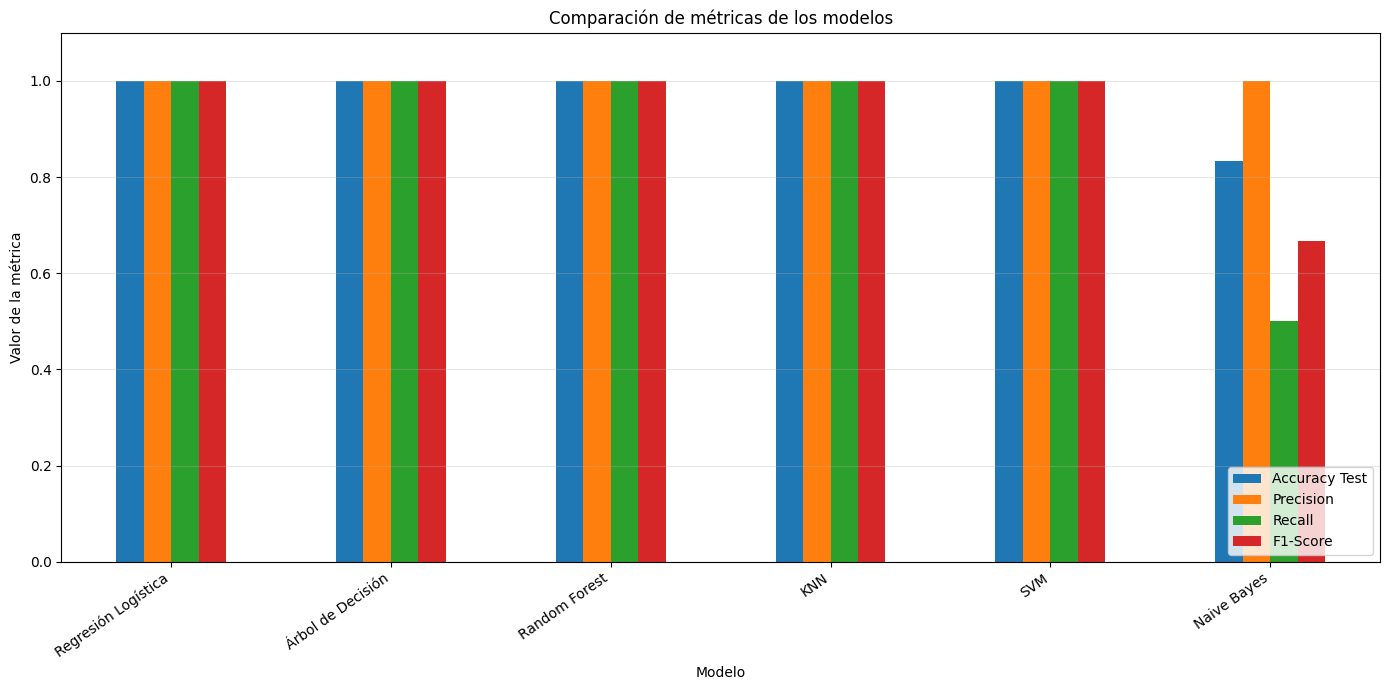

In [ ]:
# Preparar métricas principales
metricas_grafico = df_resultados.set_index("Modelo")[
    [
        "Accuracy Test",
        "Precision",
        "Recall",
        "F1-Score"
    ]
]

# //Comparar modelos
metricas_grafico.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparación de métricas de los modelos")
plt.ylabel("Valor de la métrica")
plt.xlabel("Modelo")
plt.ylim(0, 1.1)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Comparar rendimiento en entrenamiento y prueba
comparacion_overfitting = df_resultados[
    [
        "Modelo",
        "Accuracy Train",
        "Accuracy Test"
    ]
].copy()

comparacion_overfitting["Diferencia"] = (
    comparacion_overfitting["Accuracy Train"]
    - comparacion_overfitting["Accuracy Test"]
)

display(
    comparacion_overfitting.style.format({
        "Accuracy Train": "{:.3f}",
        "Accuracy Test": "{:.3f}",
        "Diferencia": "{:.3f}"
    })
)

,Modelo,Accuracy Train,Accuracy Test,Diferencia
0,Regresión Logística,1.000,1.000,0.000
1,Árbol de Decisión,1.000,1.000,0.000
2,Random Forest,1.000,1.000,0.000
3,KNN,1.000,1.000,0.000
4,SVM,1.000,1.000,0.000
5,Naive Bayes,1.000,0.833,0.167


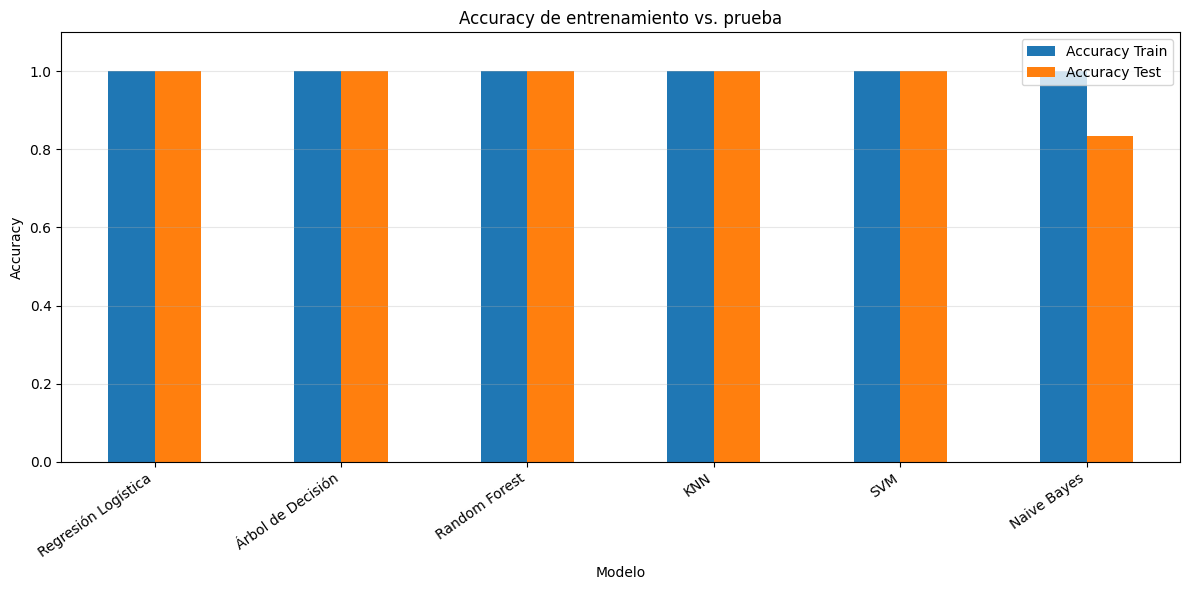

In [ ]:
# Comparación visual entre entrenamiento y prueba
comparacion_overfitting.set_index("Modelo")[
    ["Accuracy Train", "Accuracy Test"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Accuracy de entrenamiento vs. prueba")
plt.ylabel("Accuracy")
plt.xlabel("Modelo")
plt.ylim(0, 1.1)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Modelo con mayor F1-Score
mejor_modelo_f1 = df_resultados.iloc[0]

print("Modelo con mayor F1-Score:")
print(mejor_modelo_f1["Modelo"])

print("\nF1-Score:")
print(round(mejor_modelo_f1["F1-Score"], 3))

print("\nAccuracy:")
print(round(mejor_modelo_f1["Accuracy Test"], 3))

print("\nPrecision:")
print(round(mejor_modelo_f1["Precision"], 3))

print("\nRecall:")
print(round(mejor_modelo_f1["Recall"], 3))

Modelo con mayor F1-Score:
Regresión Logística

F1-Score:
1.0

Accuracy:
1.0

Precision:
1.0

Recall:
1.0


In [ ]:
# Entrenar Random Forest para analizar importancia de variables
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

# Obtener importancia
importancias = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
).reset_index(drop=True)

display(importancias)

,Variable,Importancia
0,satisfaccion,0.23
1,edad,0.22
2,horas_extra,0.21
3,salario,0.19
4,años_empresa,0.15


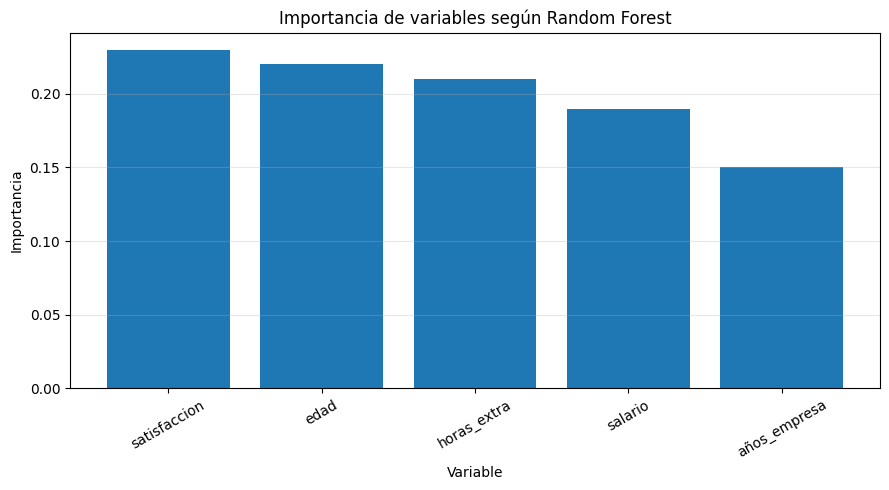

In [ ]:
# Visualizar importancia de variables
plt.figure(figsize=(9, 5))

plt.bar(
    importancias["Variable"],
    importancias["Importancia"]
)

plt.title("Importancia de variables según Random Forest")
plt.xlabel("Variable")
plt.ylabel("Importancia")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Copia del dataset para el modelo ampliado
df_ampliado = df.copy()

# Variables adicionales simuladas en escala de 1 a 10
df_ampliado["clima_laboral"] = [
    3, 4, 7, 8, 4, 9, 6, 3, 9, 7,
    3, 6, 8, 7, 4, 9, 2, 8, 8, 6
]

df_ampliado["liderazgo"] = [
    4, 5, 7, 8, 4, 9, 6, 4, 9, 8,
    3, 7, 8, 7, 5, 9, 2, 8, 8, 6
]

df_ampliado.head()

,edad,salario,años_empresa,satisfaccion,horas_extra,renuncia,clima_laboral,liderazgo
0,25,1800,1,2,15,1,3,4
1,28,2000,2,3,12,1,4,5
2,35,3500,5,7,5,0,7,7
3,40,4500,8,8,4,0,8,8
4,30,2200,2,3,14,1,4,4


In [ ]:
# Variables del modelo ampliado
X_ampliado = df_ampliado[
    [
        "edad",
        "salario",
        "años_empresa",
        "satisfaccion",
        "horas_extra",
        "clima_laboral",
        "liderazgo"
    ]
]

y_ampliado = df_ampliado["renuncia"]

# Separar datos
X_train_amp, X_test_amp, y_train_amp, y_test_amp = train_test_split(
    X_ampliado,
    y_ampliado,
    test_size=0.30,
    random_state=42,
    stratify=y_ampliado
)

print("Variables del modelo ampliado:")
print(X_ampliado.columns.tolist())

Variables del modelo ampliado:
['edad', 'salario', 'años_empresa', 'satisfaccion', 'horas_extra', 'clima_laboral', 'liderazgo']


In [ ]:
# Modelo original
rf_original = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_original.fit(X_train, y_train)

pred_original = rf_original.predict(X_test)

# Modelo ampliado
rf_ampliado = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_ampliado.fit(
    X_train_amp,
    y_train_amp
)

pred_ampliado = rf_ampliado.predict(
    X_test_amp
)

# Comparar resultados
comparacion_variables = pd.DataFrame({
    "Modelo": [
        "Variables originales",
        "Variables + Clima + Liderazgo"
    ],

    "Accuracy": [
        accuracy_score(y_test, pred_original),
        accuracy_score(y_test_amp, pred_ampliado)
    ],

    "Precision": [
        precision_score(
            y_test,
            pred_original,
            zero_division=0
        ),
        precision_score(
            y_test_amp,
            pred_ampliado,
            zero_division=0
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            pred_original,
            zero_division=0
        ),
        recall_score(
            y_test_amp,
            pred_ampliado,
            zero_division=0
        )
    ],

    "F1-Score": [
        f1_score(
            y_test,
            pred_original,
            zero_division=0
        ),
        f1_score(
            y_test_amp,
            pred_ampliado,
            zero_division=0
        )
    ]
})

display(
    comparacion_variables.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-Score": "{:.3f}"
    })
)

,Modelo,Accuracy,Precision,Recall,F1-Score
0,Variables originales,1.000,1.000,1.000,1.000
1,Variables + Clima + Liderazgo,1.000,1.000,1.000,1.000


In [ ]:
# Importancia de variables del modelo ampliado
importancias_ampliado = pd.DataFrame({
    "Variable": X_ampliado.columns,
    "Importancia": rf_ampliado.feature_importances_
})

importancias_ampliado = importancias_ampliado.sort_values(
    by="Importancia",
    ascending=False
).reset_index(drop=True)

display(importancias_ampliado)

,Variable,Importancia
0,salario,0.18
1,edad,0.17
2,clima_laboral,0.17
3,años_empresa,0.15
4,liderazgo,0.15
5,horas_extra,0.09
6,satisfaccion,0.09


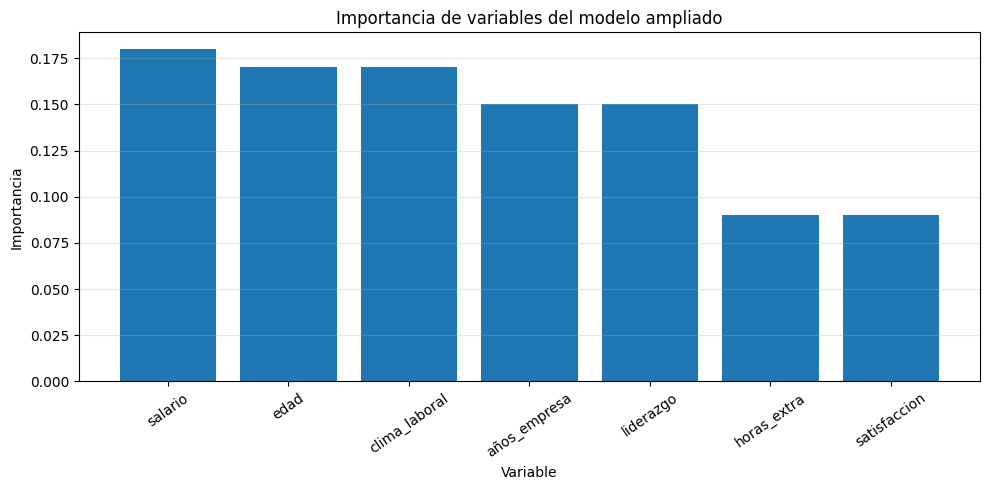

In [ ]:
# Importancia de variables incluyendo Clima y Liderazgo
plt.figure(figsize=(10, 5))

plt.bar(
    importancias_ampliado["Variable"],
    importancias_ampliado["Importancia"]
)

plt.title("Importancia de variables del modelo ampliado")
plt.xlabel("Variable")
plt.ylabel("Importancia")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Ejemplo de un empleado nuevo
nuevo_empleado = pd.DataFrame({
    "edad": [29],
    "salario": [2100],
    "años_empresa": [2],
    "satisfaccion": [3],
    "horas_extra": [14]
})

# Usar el modelo con mejor F1
nombre_mejor_modelo = df_resultados.iloc[0]["Modelo"]

modelo_final = modelos[nombre_mejor_modelo]

modelo_final.fit(X, y)

prediccion = modelo_final.predict(
    nuevo_empleado
)

print("Modelo utilizado:", nombre_mejor_modelo)

if prediccion[0] == 1:
    print("Predicción: El empleado podría renunciar.")
else:
    print("Predicción: El empleado podría permanecer en la empresa.")

Modelo utilizado: Regresión Logística
Predicción: El empleado podría renunciar.


In [ ]:
# Guardar resultados para GitHub
df.to_csv(
    "dataset_rrhh.csv",
    index=False
)

df_ampliado.to_csv(
    "dataset_rrhh_ampliado.csv",
    index=False
)

df_resultados.to_csv(
    "resultados_modelos.csv",
    index=False
)

comparacion_variables.to_csv(
    "comparacion_variables_adicionales.csv",
    index=False
)

importancias.to_csv(
    "importancia_variables.csv",
    index=False
)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.


In [ ]:
# Archivos creados durante el análisis
import os

for archivo in os.listdir():
    if archivo.endswith(".csv"):
        print(archivo)

dataset_rrhh_ampliado.csv
comparacion_variables_adicionales.csv
dataset_rrhh.csv
resultados_modelos.csv
importancia_variables.csv
